In [ ]:
!pip install -q datasets transformers accelerate scikit-learn

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU undetected!")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
# Import Libraries
import datasets
import pandas as pd

In [ ]:
# Load datasets from AG News
ag_news = datasets.load_dataset("fancyzhx/ag_news")

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [ ]:
# Change to pandas
train_ds = ag_news["train"]
df_train = train_ds.to_pandas()

test_ds = ag_news["test"]
df_test = test_ds.to_pandas()

In [ ]:
label_mapping = {0: "World", 1: "Sports", 2: "Business",3: "Sci/Tech"}

df_train["category"] = df_train["label"].map(label_mapping)
df_test["category"] = df_test["label"].map(label_mapping)

print(df_train[["text", "label", "category"]].head())
print(df_test[["text", "label", "category"]].head())

                                                text  label  category
0  Wall St. Bears Claw Back Into the Black (Reute...      2  Business
1  Carlyle Looks Toward Commercial Aerospace (Reu...      2  Business
2  Oil and Economy Cloud Stocks' Outlook (Reuters...      2  Business
3  Iraq Halts Oil Exports from Main Southern Pipe...      2  Business
4  Oil prices soar to all-time record, posing new...      2  Business
                                                text  label  category
0  Fears for T N pension after talks Unions repre...      2  Business
1  The Race is On: Second Private Team Sets Launc...      3  Sci/Tech
2  Ky. Company Wins Grant to Study Peptides (AP) ...      3  Sci/Tech
3  Prediction Unit Helps Forecast Wildfires (AP) ...      3  Sci/Tech
4  Calif. Aims to Limit Farm-Related Smog (AP) AP...      3  Sci/Tech


In [ ]:
import re
import html

def clean_text(text):
    # 1. Decode standard HTML entities
    text = html.unescape(text)

    # 2. Fix remaining HTML entity fragments
    text = text.replace("#39;", "'")
    text = re.sub(r"(?<=\s)amp;", "&", text, flags=re.IGNORECASE)
    text = re.sub(r"(?<=\s)quot;", '"', text, flags=re.IGNORECASE)
    text = re.sub(r"(?<=\s)(?:lt|gt);", " ", text, flags=re.IGNORECASE)

    # 3. Remove pseudo-HTML tags: <b>, <p>, <a href=...>, </strong>
    text = re.sub(r"<[^>]+>", " ", text)

    # 4. Remove URLs and email addresses
    text = re.sub(r"https?://\S*|www\.\S*", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", " ", text)

    # 5. Remove source attribution inside parentheses: (AP-CP), (Reuters)
    text = re.sub(r"\s*\((?:Reuters|AP|AFP)(?:-[A-Za-z]+)?\)", "", text, flags=re.IGNORECASE)

    # 6. Remove source attribution after title: AP - / Reuters -
    text = re.sub(r"\s+\b(?:Reuters|AP|AFP)\s*-\s*", " ", text, flags=re.IGNORECASE)

    # 7. Remove incomplete parenthesized attribution: (AFP -
    text = re.sub(r"\s*\((?:Reuters|AP|AFP)\s*-\s*", " ", text, flags=re.IGNORECASE)

    # 8. Remove news codes at the beginning: AP-Italy-Alitalia
    text = re.sub(r"^(?:AP|AFP|Reuters)-[A-Za-z0-9]+(?:-[A-Za-z0-9]+)*\s+", "", text, flags=re.IGNORECASE)

    # 9. Remove source attribution after a slash: UC Davis/AP --
    text = re.sub(r"/(?:Reuters|AP|AFP)\s*--?\s*", " ", text, flags=re.IGNORECASE)

    # 10. Remove escaped dollar signs and remaining backslashes
    text = text.replace("\\$", "$")
    text = text.replace("\\", " ")

    # 11. Lowercase
    text = text.lower()

    # 12. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
df_train["clean_text"] = df_train["text"].apply(clean_text)
df_test["clean_text"] = df_test["text"].apply(clean_text)

In [ ]:
# Identify texts with conflicting labels
duplicate_labels = (df_train.groupby("clean_text")["label"].nunique())

conflicting_texts = duplicate_labels[duplicate_labels > 1].index

# Remove all conflicting texts
df_train = df_train[~df_train["clean_text"].isin(conflicting_texts)].copy()

# Remove remaining duplicates with consistent labels
df_train = df_train.drop_duplicates(subset="clean_text",keep="first").copy()

print("Train duplicates after cleaning:", df_train["clean_text"].duplicated().sum())

Train duplicates after cleaning: 0


In [ ]:
overlap = (set(df_train["clean_text"]) & set(df_test["clean_text"]))
df_train = df_train[~df_train["clean_text"].isin(overlap)].copy()

print("Train-Test overlap after cleaning:",len(set(df_train["clean_text"]) & set(df_test["clean_text"])))

Train-Test overlap after cleaning: 0


In [ ]:
x_train = df_train["clean_text"]
y_train = df_train["label"]

x_test = df_test["clean_text"]
y_test = df_test["label"]

In [ ]:
print("X_train:", x_train.shape)
print("y_train:", y_train.shape)
print("X_test:", x_test.shape)
print("y_test:", y_test.shape)

X_train: (119299,)
y_train: (119299,)
X_test: (7600,)
y_test: (7600,)


In [ ]:
from sklearn.model_selection import train_test_split

x_fit, x_val, y_fit, y_val = train_test_split(x_train, y_train, test_size=0.1, stratify=y_train, random_state=42)

In [ ]:
print("X_fit:", x_fit.shape)
print("X_val:", x_val.shape)
print("y_fit:", y_fit.shape)
print("y_val:", y_val.shape)

X_fit: (107369,)
X_val: (11930,)
y_fit: (107369,)
y_val: (11930,)


In [ ]:
from datasets import Dataset
# Dataset
df_fit = pd.DataFrame({"text": x_fit.tolist(), "label": y_fit.tolist()})
df_val = pd.DataFrame({"text": x_val.tolist(), "label": y_val.tolist()})
df_test_distilbert = pd.DataFrame({"text": x_test.tolist(), "label": y_test.tolist()})

# Reset index
df_fit = df_fit.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test_distilbert = df_test_distilbert.reset_index(drop=True)

# Converstion to hugging face dataset from pandas
dataset_fit = Dataset.from_pandas(df_fit, preserve_index=False)
dataset_val = Dataset.from_pandas(df_val, preserve_index=False)
dataset_test = Dataset.from_pandas(df_test_distilbert, preserve_index=False)

print("Training:", dataset_fit)
print("Validation:", dataset_val)
print("Testing:", dataset_test)

Training: Dataset({
    features: ['text', 'label'],
    num_rows: 107369
})
Validation: Dataset({
    features: ['text', 'label'],
    num_rows: 11930
})
Testing: Dataset({
    features: ['text', 'label'],
    num_rows: 7600
})


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
print("Tokenizer loaded!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded!


In [ ]:
import numpy as np

sample_texts = x_fit.sample(n=5000, random_state=42).tolist()

token_lengths = [
    len(tokenizer(text, truncation=False)["input_ids"])
    for text in sample_texts
]

p95 = np.percentile(token_lengths, 95)
p99 = np.percentile(token_lengths, 99)
max_tokens = max(token_lengths)

print("95th percentile:", p95)
print("99th percentile:", p99)
print("Maximum tokens:", max_tokens)

95th percentile: 70.0
99th percentile: 92.01000000000022
Maximum tokens: 177


In [ ]:
MAX_LENGTH = 128

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_fit = dataset_fit.map(tokenize_function, batched=True)
tokenized_val = dataset_val.map(tokenize_function, batched=True)
tokenized_test = dataset_test.map(tokenize_function, batched=True)

print(tokenized_fit)

Map:   0%|          | 0/107369 [00:00<?, ? examples/s]

Map:   0%|          | 0/11930 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 107369
})


In [ ]:
import numpy as np
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score ,classification_report, confusion_matrix

In [ ]:
id2label = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

label2id = {
    label: id
    for id, label in id2label.items()
}

print("ID to Label:", id2label)
print("Label to ID:", label2id)

ID to Label: {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}
Label to ID: {'World': 0, 'Sports': 1, 'Business': 2, 'Sci/Tech': 3}


In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

model.to("cuda")

print("Model loaded!")
print("Device:", next(model.parameters()).device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model berhasil dimuat!
Device: cuda:0


In [ ]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(labels, predictions, average="macro")

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

In [ ]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./distilbert-agnews",

    # Training
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=0.1,

    # Evaluation
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    # Performance
    fp16=True,

    # Logging
    logging_steps=100,
    save_total_limit=2,
    report_to="none",

    # Reproducibility
    seed=42
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_fit,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.220549,0.211901,0.930511,0.930679
2,0.169913,0.204861,0.939732,0.939714
3,0.118271,0.234621,0.938977,0.939000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation Macro F1:", trainer.state.best_metric)

Best checkpoint: ./distilbert-agnews/checkpoint-13422
Best validation Macro F1: 0.9397135119973432


In [ ]:
test_results = trainer.evaluate(tokenized_test)

print("\n=== DISTILBERT TEST RESULTS ===")
print(f"Test Loss: {test_results['eval_loss']:.4f}")
print(f"Accuracy: {test_results['eval_accuracy']:.4f}")
print(f"Macro F1: {test_results['eval_macro_f1']:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.118271,0.215460,3,0.938026,0.938043



=== DISTILBERT TEST RESULTS ===
Test Loss: 0.2155
Accuracy: 0.9380
Macro F1: 0.9380


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

       World     0.9638    0.9258    0.9444      1900
      Sports     0.9787    0.9900    0.9843      1900
    Business     0.9073    0.9011    0.9041      1900
    Sci/Tech     0.9039    0.9353    0.9193      1900

    accuracy                         0.9380      7600
   macro avg     0.9384    0.9380    0.9380      7600
weighted avg     0.9384    0.9380    0.9380      7600



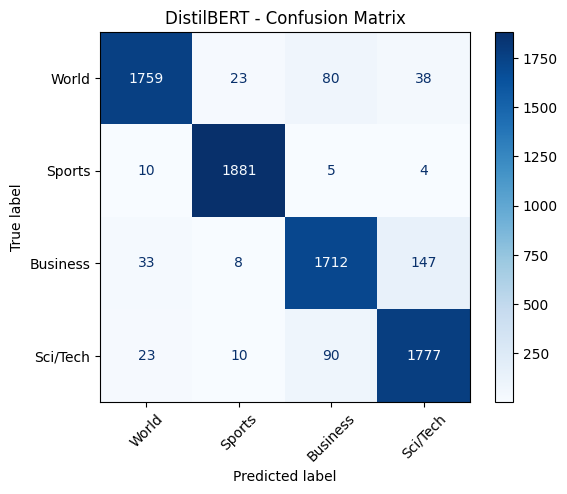

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

predictions = trainer.predict(tokenized_test)

y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

# Classification Report
print("=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_true,
    y_pred,
    target_names=["World", "Sports", "Business", "Sci/Tech"],
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["World", "Sports", "Business", "Sci/Tech"])

disp.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT - Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

### Probability Quality and Confidence-Based Routing
DistilBERT gives logits, so softmax turns them into class probabilities. The same evaluation as the classical models is used: log-loss and ROC-AUC on the test set, and a confidence threshold chosen on the **validation set** (lowest threshold with auto-filed accuracy ≥ 95%), then applied unchanged to the test set.

In [ ]:
from sklearn.metrics import log_loss, roc_auc_score

# 1. Convert logits into probabilities with softmax
def softmax(logits):
    exp_logits = np.exp(logits - logits.max(axis=1, keepdims=True))
    return exp_logits / exp_logits.sum(axis=1, keepdims=True)

val_output = trainer.predict(tokenized_val)

val_probabilities = softmax(val_output.predictions)
test_probabilities = softmax(predictions.predictions)

y_val_true = val_output.label_ids

# 2. Probability quality on the test set
distilbert_log_loss = log_loss(y_true, test_probabilities, labels=[0, 1, 2, 3])
distilbert_roc_auc = roc_auc_score(y_true, test_probabilities, multi_class="ovr", average="macro", labels=[0, 1, 2, 3])

print(f"Log-loss      : {distilbert_log_loss:.4f}")
print(f"ROC-AUC (OvR) : {distilbert_roc_auc:.4f}")

Log-loss      : 0.2155
ROC-AUC (OvR) : 0.9911


In [ ]:
# 1. Candidate confidence thresholds and the business target
thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]
TARGET_ACCURACY = 0.95

# 2. Coverage and auto-filed accuracy for each threshold on the VALIDATION set
val_confidence = val_probabilities.max(axis=1)
val_prediction = val_probabilities.argmax(axis=1)

routing_curve = []

for threshold in thresholds:
    auto_filed = val_confidence >= threshold

    routing_curve.append({
        "Threshold": threshold,
        "Coverage": auto_filed.mean(),
        "Auto-filed Accuracy": accuracy_score(y_val_true[auto_filed], val_prediction[auto_filed]) if auto_filed.any() else 0
    })

routing_curve_df = pd.DataFrame(routing_curve)
display(routing_curve_df)

# 3. Choose the lowest threshold that keeps validation accuracy >= 95%
reached = routing_curve_df[routing_curve_df["Auto-filed Accuracy"] >= TARGET_ACCURACY]
distilbert_threshold = reached["Threshold"].min()

# 4. Apply the selected threshold unchanged to the TEST set
test_confidence = test_probabilities.max(axis=1)
test_auto_filed = test_confidence >= distilbert_threshold

distilbert_test_coverage = test_auto_filed.mean()
distilbert_test_auto_accuracy = accuracy_score(y_true[test_auto_filed], y_pred[test_auto_filed])

print(f"Threshold (from validation): {distilbert_threshold}")
print(f"Test Coverage              : {distilbert_test_coverage:.4f}")
print(f"Test Auto-filed Accuracy   : {distilbert_test_auto_accuracy:.4f}")
print(f"Sent to Editor (%)         : {(1 - distilbert_test_coverage) * 100:.2f}")

,Threshold,Coverage,Auto-filed Accuracy
0,0.50,0.998659,0.940574
1,0.55,0.991534,0.944289
2,0.60,0.986840,0.945978
3,0.65,0.981643,0.948083
4,0.70,0.975440,0.950417
5,0.75,0.969153,0.952084
6,0.80,0.959514,0.954748
7,0.85,0.946773,0.958831
8,0.90,0.925733,0.965049
9,0.95,0.883906,0.973068


Threshold (from validation): 0.7
Test Coverage              : 0.9736
Test Auto-filed Accuracy   : 0.9490
Sent to Editor (%)         : 2.64


In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
FOLDER = "/content/drive/MyDrive/news-lens/models"
MODEL_DIR = os.path.join(FOLDER, "distilbert-agnews")

os.makedirs(MODEL_DIR, exist_ok=True)

# Save best fine-tuned model
trainer.save_model(MODEL_DIR)

tokenizer.save_pretrained(MODEL_DIR)

print("DistilBERT saved!")
print("Location:", MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT saved!
Location: /content/drive/MyDrive/news-lens/models/distilbert-agnews


In [ ]:
# Overall metrics
distilbert_results = pd.DataFrame([{
    "Model": "DistilBERT",
    "Accuracy": test_results["eval_accuracy"],
    "Macro Precision": precision_score(y_true, y_pred, average="macro"),
    "Macro Recall": recall_score(y_true, y_pred, average="macro"),
    "Macro F1": test_results["eval_macro_f1"],
    "Test Loss": test_results["eval_loss"],
    "Log-loss": distilbert_log_loss,
    "ROC-AUC (OvR)": distilbert_roc_auc
}])

# Classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=["World", "Sports", "Business", "Sci/Tech"],
    output_dict=True
)

distilbert_report = pd.DataFrame(report).transpose()

# Save to Google Drive
distilbert_results.to_csv(os.path.join(FOLDER, "distilbert_test_results.csv"), index=False)
distilbert_report.to_csv(os.path.join(FOLDER, "distilbert_classification_report.csv"))

print("Evaluation results saved!")
print(distilbert_results)

Evaluation results saved!
        Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Test Loss  \
0  DistilBERT  0.938026         0.938407      0.938026  0.938043    0.21546   

   Log-loss  ROC-AUC (OvR)  
0  0.215458       0.991109  


In [ ]:
classical_results_df = pd.read_csv(os.path.join(FOLDER, "final_summary.csv"))

classical_results_df = classical_results_df.rename(columns={
    "Precision": "Macro Precision",
    "Recall": "Macro Recall",
    "Prediction Time (ms/article)": "Time per Article (ms)"
})

distilbert_results_df = pd.DataFrame([{
    "Model": "DistilBERT",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(y_true, y_pred, average="macro"),
    "Macro Recall": recall_score(y_true, y_pred, average="macro"),
    "Macro-F1": f1_score(y_true, y_pred, average="macro"),
    "Prediction Time (s)": predictions.metrics["test_runtime"],
    "Time per Article (ms)": predictions.metrics["test_runtime"] / len(y_true) * 1000,
    "Model Size (MB)": os.path.getsize(os.path.join(MODEL_DIR, "model.safetensors")) / (1024 ** 2),
    "Training Time (s)": train_result.metrics["train_runtime"],
    "Log-loss": distilbert_log_loss,
    "ROC-AUC (OvR)": distilbert_roc_auc,
    "Threshold (from validation)": distilbert_threshold,
    "Test Coverage": distilbert_test_coverage,
    "Test Auto-filed Accuracy": distilbert_test_auto_accuracy
}])

# Classical models run on CPU in Colab, DistilBERT runs on the T4 GPU
classical_results_df["Device"] = "CPU"
distilbert_results_df["Device"] = "GPU (T4)"

final_comparison = pd.concat([classical_results_df, distilbert_results_df], ignore_index=True)
final_comparison = final_comparison.sort_values("Macro-F1", ascending=False).reset_index(drop=True)
final_comparison.insert(0, "Rank", range(1, len(final_comparison) + 1))
display(final_comparison.round(4))

final_comparison.to_csv(os.path.join(FOLDER, "final_comparison.csv"),index=False)

,Rank,Model,Macro-F1,Accuracy,Macro Precision,Macro Recall,Prediction Time (s),Time per Article (ms),Model Size (MB),Training Time (s),Log-loss,ROC-AUC (OvR),Threshold (from validation),Test Coverage,Test Auto-filed Accuracy,Device
0,1,DistilBERT,0.9380,0.9380,0.9384,0.9380,5.1128,0.6727,255.4309,1015.6208,0.2155,0.9911,0.70,0.9736,0.9490,GPU (T4)
1,2,Linear SVC,0.9177,0.9179,0.9178,0.9179,0.0037,0.0005,1.5265,10.8213,NaN,NaN,NaN,NaN,NaN,CPU
2,3,Linear SVC (Calibrated),0.9158,0.9159,0.9159,0.9159,0.0250,0.0033,4.5798,45.9906,0.2684,0.9823,0.70,0.9022,0.9503,CPU
3,4,Logistic Regression,0.9117,0.9118,0.9117,0.9118,0.0090,0.0012,1.5266,24.4271,0.2994,0.9812,0.65,0.8772,0.9489,CPU
4,5,Multinomial NB,0.9058,0.9061,0.9059,0.9061,0.0104,0.0014,3.0524,0.0518,0.3624,0.9783,0.85,0.8678,0.9484,CPU
5,6,K-Nearest Neighbors,0.9049,0.9053,0.9049,0.9053,80.7934,10.6307,32.9581,0.0169,0.5086,0.9804,0.65,0.8679,0.9472,CPU
6,7,Random Forest,0.8864,0.8868,0.8863,0.8868,3.6579,0.4813,471.2090,503.4058,0.4011,0.9755,0.70,0.7501,0.9537,CPU
7,8,Decision Tree,0.8122,0.8124,0.8121,0.8124,0.0286,0.0038,2.1447,207.0618,6.7585,0.8750,NaN,NaN,NaN,CPU
